# Transport-Plan Sparsification Methods



In [1]:
%load_ext autoreload
%autoreload 2

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import scipy.sparse as sp

sys.path.insert(0, "../src")

from ne_aligned_utils.data import make_fig1_data, make_joint_gmm

from ne_aligned_utils.toy_utils import (
    make_circle_data,
    compute_ot_plan,
    get_diag_graph,
    sparsify_sym,
    aligned_tsne,
    compute_foscttm,
)
from ne_aligned_utils.utils import sparsify_affinities
from ne_aligned_utils.metrics import compute_cross_concordance
from ne_aligned_utils.transport_plan_sparsify import sparsify_transport_plan

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True


In [2]:
# -------------------------------
# Config
# -------------------------------
seed_demo = 0
sweep_seeds = [0, 1, 2, 3, 4]

percentages = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
methods = [
    "percentage_neighbors",
    "percentage_mass",
    "percentage_below_top",
]

method_labels = {
    "percentage_neighbors": "Percentage neighbors",
    "percentage_mass": "Percentage mass",
    "percentage_below_top": "Percentage below top",
}

# toy data settings
n0 = 1000
n1 = 5000
eps_times = 1
n_iter = 10000
n_epochs = 200
cross_k = 50
below_top_scale_exponent = 2.0

# baseline (classic sym sparse diag)
baseline_k = 15

# graph used for method comparison t-SNE
scaled_bin_k = 15
scaled_bin_symmetric = True

# reweight cross-modality blocks (A01, A10) before graph sparsification
cross_block_alpha = 1.0
alpha_values_compare = [1.0, 1.5, 2.0, 3.0]
alpha_compare_method = "percentage_neighbors"
alpha_compare_percentage = 0.30

# preview settings for matrix plots
preview_side = 500

# paths
data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)
plan_cache_dir = data_dir
run_cache_dir = data_dir / "toy_sparsify_scaled_bin_sym"
run_cache_dir.mkdir(parents=True, exist_ok=True)
no_aff_cache_dir = data_dir / "toy_sparsify_no_scaled_bin_sym"
no_aff_cache_dir.mkdir(parents=True, exist_ok=True)
baseline_cache_dir = data_dir / "toy_baseline_sym_sparse_diag"
baseline_cache_dir.mkdir(parents=True, exist_ok=True)


In [3]:
# -------------------------------
# Helpers
# -------------------------------
METRIC_REFERENCE = f"fig1_clean_2d_v3_rowmass_belowtopexp_{below_top_scale_exponent:.2f}"


def _pct_tag(p):
    return f"{p:.3f}".replace(".", "p")


def _alpha_tag(a):
    return f"{float(a):.2f}".replace(".", "p")


def _bte_tag(v):
    return f"{float(v):.2f}".replace(".", "p")


def plan_file_path(seed):
    return plan_cache_dir / f"ot_plan_toy_n0{n0}_n1{n1}_seed{seed}_epstimes{eps_times}.npz"


def run_file_path(seed, method, percentage, cross_alpha=None):
    alpha = cross_block_alpha if cross_alpha is None else float(cross_alpha)
    return run_cache_dir / (
        f"seed{seed}_{method}_pct{_pct_tag(percentage)}_alpha{_alpha_tag(alpha)}_bte{_bte_tag(below_top_scale_exponent)}.npz"
    )


def baseline_file_path(seed, cross_alpha=None):
    alpha = cross_block_alpha if cross_alpha is None else float(cross_alpha)
    return baseline_cache_dir / f"seed{seed}_baseline_sym_sparse_diag_k{baseline_k}_alpha{_alpha_tag(alpha)}.npz"


def load_or_compute_plan(seed):
    path = plan_file_path(seed)
    if path.exists():
        data = np.load(path)
        return data["x0"], data["x1"], data["P"]

    x0, x1 = make_circle_data(n0=n0, n1=n1, seed=seed)
    P = compute_ot_plan(x0, x1, eps_times=eps_times, n_iter=n_iter)
    np.savez(path, P=P, x0=x0, x1=x1, n0=n0, n1=n1, seed=seed, eps_times=eps_times)
    return x0, x1, P


def load_clean_reference(seed, n0_ref=None, n1_ref=None):
    if n0_ref is None:
        n0_ref = n0
    if n1_ref is None:
        n1_ref = n1
    clean0, clean1 = make_fig1_data(n0=n0_ref, n1=n1_ref, seed=seed, clean=True)
    return clean0, clean1


def reweight_cross_blocks(A, n0_block, alpha=1.0, renormalize=True):
    A_rw = np.array(A, copy=True)
    if not np.isclose(alpha, 1.0):
        A_rw[:n0_block, n0_block:] *= alpha
        A_rw[n0_block:, :n0_block] *= alpha
    if renormalize:
        s = A_rw.sum()
        if s > 0:
            A_rw /= s
    return A_rw


def block_mass_stats(A, n0_block):
    b00 = float(A[:n0_block, :n0_block].sum())
    b01 = float(A[:n0_block, n0_block:].sum())
    b10 = float(A[n0_block:, :n0_block].sum())
    b11 = float(A[n0_block:, n0_block:].sum())
    total = b00 + b01 + b10 + b11
    cross_share = (b01 + b10) / total if total > 0 else np.nan
    return {
        "b00": b00,
        "b01": b01,
        "b10": b10,
        "b11": b11,
        "total": total,
        "cross_share": cross_share,
    }


def _downsample_dense(A, max_side=500):
    step = max(1, int(np.ceil(A.shape[0] / max_side)))
    return np.asarray(A[::step, ::step]), step


def _downsample_sparse(S, max_side=500):
    step = max(1, int(np.ceil(S.shape[0] / max_side)))
    return S[::step, ::step].toarray(), step


def _block_boundary(shape0):
    return int(round((n0 / (n0 + n1)) * shape0))


def _load_run(path):
    run = np.load(path, allow_pickle=True)
    required = [
        "seed",
        "method",
        "percentage",
        "cross_block_alpha",
        "below_top_scale_exponent",
        "embd",
        "foscttm",
        "foscttm_observed",
        "cross_concordance",
        "plan_nnz",
        "plan_density",
        "plan_retained_mass_before_renorm",
        "row_nonzero_min",
        "col_nonzero_min",
        "graph_nnz",
        "graph_density",
        "embedding_all_finite",
        "time_sparsify",
        "time_graph",
        "time_tsne",
        "matrix_preview",
        "block_cross_share",
        "metric_reference",
    ]
    missing = [k for k in required if k not in run.files]
    if missing:
        raise KeyError(f"Missing keys in cache: {missing}")

    metric_reference = str(run["metric_reference"])
    if metric_reference != METRIC_REFERENCE:
        raise KeyError(f"Cache metric_reference={metric_reference}, expected {METRIC_REFERENCE}")

    below_top_exp = float(run["below_top_scale_exponent"])
    if not np.isclose(below_top_exp, below_top_scale_exponent):
        raise KeyError(f"Cache below_top_scale_exponent={below_top_exp}, expected {below_top_scale_exponent}")

    return {
        "seed": int(run["seed"]),
        "method": str(run["method"]),
        "percentage": float(run["percentage"]),
        "cross_block_alpha": float(run["cross_block_alpha"]),
        "below_top_scale_exponent": below_top_exp,
        "embd": run["embd"],
        "foscttm": float(run["foscttm"]),
        "foscttm_observed": float(run["foscttm_observed"]),
        "cross_concordance": float(run["cross_concordance"]),
        "plan_nnz": int(run["plan_nnz"]),
        "plan_density": float(run["plan_density"]),
        "plan_retained_mass_before_renorm": float(run["plan_retained_mass_before_renorm"]),
        "row_nonzero_min": int(run["row_nonzero_min"]),
        "col_nonzero_min": int(run["col_nonzero_min"]),
        "graph_nnz": int(run["graph_nnz"]),
        "graph_density": float(run["graph_density"]),
        "embedding_all_finite": bool(run["embedding_all_finite"]),
        "time_sparsify": float(run["time_sparsify"]),
        "time_graph": float(run["time_graph"]),
        "time_tsne": float(run["time_tsne"]),
        "matrix_preview": run["matrix_preview"],
        "block_cross_share": float(run["block_cross_share"]),
        "metric_reference": metric_reference,
    }


def run_setting(seed, method, percentage, recompute=False, cross_alpha=None):
    alpha = cross_block_alpha if cross_alpha is None else float(cross_alpha)
    path = run_file_path(seed, method, percentage, cross_alpha=alpha)
    if path.exists() and not recompute:
        try:
            out = _load_run(path)
            if not np.isclose(out["cross_block_alpha"], alpha):
                raise KeyError("cross_block_alpha mismatch")
            return out
        except KeyError:
            print(f"Legacy/incompatible cache at {path.name}; recomputing.")

    x0, x1, P = load_or_compute_plan(seed)
    n0_seed, n1_seed = x0.shape[0], x1.shape[0]
    clean0, clean1 = load_clean_reference(seed, n0_ref=n0_seed, n1_ref=n1_seed)

    t0 = time.time()
    P_sparse, stats = sparsify_transport_plan(
        P,
        method=method,
        percentage=percentage,
        ensure_nonempty=True,
        renormalize=True,
        return_stats=True,
        below_top_scale_exponent=below_top_scale_exponent,
    )
    t1 = time.time()

    A = get_diag_graph(P_sparse)
    A = reweight_cross_blocks(A, n0_block=n0_seed, alpha=alpha, renormalize=True)
    block_stats = block_mass_stats(A, n0_seed)
    matrix_preview, _ = _downsample_dense(A, max_side=preview_side)

    graph = sp.csr_matrix(
        sparsify_affinities(A, n0_seed, n1_seed, k=scaled_bin_k, symmetric=scaled_bin_symmetric)
    )
    t2 = time.time()

    embd = np.asarray(aligned_tsne(graph, n_epochs=n_epochs, seed=seed))
    t3 = time.time()

    embd0 = embd[:n0_seed]
    embd1 = embd[n0_seed:]

    foscttm = float(compute_foscttm(clean0, clean1, embd0, embd1))
    k_cross = min(cross_k, n0_seed, n1_seed)
    cross_concordance = float(compute_cross_concordance(clean0, clean1, embd0, embd1, k=k_cross))
    foscttm_observed = float(compute_foscttm(x0, x1, embd0, embd1))

    row_nonzero_min = int(np.min(np.count_nonzero(P_sparse > 0, axis=1)))
    col_nonzero_min = int(np.min(np.count_nonzero(P_sparse > 0, axis=0)))
    embedding_all_finite = bool(np.isfinite(embd).all())

    np.savez(
        path,
        seed=int(seed),
        method=str(method),
        percentage=float(percentage),
        cross_block_alpha=float(alpha),
        below_top_scale_exponent=float(below_top_scale_exponent),
        embd=embd,
        foscttm=foscttm,
        foscttm_observed=foscttm_observed,
        cross_concordance=cross_concordance,
        plan_nnz=int(stats["nnz"]),
        plan_density=float(stats["density"]),
        plan_retained_mass_before_renorm=float(stats["retained_mass_before_renorm"]),
        row_nonzero_min=row_nonzero_min,
        col_nonzero_min=col_nonzero_min,
        graph_nnz=int(graph.nnz),
        graph_density=float(graph.nnz / (graph.shape[0] * graph.shape[1])),
        embedding_all_finite=embedding_all_finite,
        time_sparsify=float(t1 - t0),
        time_graph=float(t2 - t1),
        time_tsne=float(t3 - t2),
        matrix_preview=matrix_preview.astype(np.float32),
        block_cross_share=float(block_stats["cross_share"]),
        metric_reference=METRIC_REFERENCE,
    )

    return _load_run(path)


def run_baseline_sym_sparse_diag(seed, recompute=False, cross_alpha=None):
    alpha = cross_block_alpha if cross_alpha is None else float(cross_alpha)
    path = baseline_file_path(seed, cross_alpha=alpha)
    if path.exists() and not recompute:
        out = np.load(path, allow_pickle=True)
        required = [
            "embd",
            "foscttm",
            "cross_concordance",
            "graph_nnz",
            "graph_density",
            "matrix_preview",
            "time_graph",
            "time_tsne",
            "cross_block_alpha",
            "block_cross_share",
            "metric_reference",
        ]
        missing = [k for k in required if k not in out.files]
        if not missing and str(out["metric_reference"]) == METRIC_REFERENCE and np.isclose(float(out["cross_block_alpha"]), alpha):
            return {
                "embd": out["embd"],
                "foscttm": float(out["foscttm"]),
                "cross_concordance": float(out["cross_concordance"]),
                "graph_nnz": int(out["graph_nnz"]),
                "graph_density": float(out["graph_density"]),
                "matrix_preview": out["matrix_preview"],
                "time_graph": float(out["time_graph"]),
                "time_tsne": float(out["time_tsne"]),
                "cross_block_alpha": float(out["cross_block_alpha"]),
                "block_cross_share": float(out["block_cross_share"]),
                "metric_reference": str(out["metric_reference"]),
            }
        print(f"Legacy/incompatible baseline cache at {path.name}; recomputing.")

    x0, x1, P = load_or_compute_plan(seed)
    clean0, clean1 = load_clean_reference(seed, n0_ref=len(x0), n1_ref=len(x1))

    t0 = time.time()
    A = get_diag_graph(P)
    A = reweight_cross_blocks(A, n0_block=len(x0), alpha=alpha, renormalize=True)
    block_stats = block_mass_stats(A, len(x0))
    graph = sparsify_sym(A, len(x0), len(x1), k=baseline_k)
    matrix_preview, _ = _downsample_sparse(graph, max_side=preview_side)
    t1 = time.time()

    embd = np.asarray(aligned_tsne(graph, n_epochs=n_epochs, seed=seed))
    t2 = time.time()

    embd0 = embd[:len(x0)]
    embd1 = embd[len(x0):]
    foscttm = float(compute_foscttm(clean0, clean1, embd0, embd1))
    k_cross = min(cross_k, len(x0), len(x1))
    cross_concordance = float(compute_cross_concordance(clean0, clean1, embd0, embd1, k=k_cross))

    np.savez(
        path,
        embd=embd,
        foscttm=foscttm,
        cross_concordance=cross_concordance,
        graph_nnz=int(graph.nnz),
        graph_density=float(graph.nnz / (graph.shape[0] * graph.shape[1])),
        matrix_preview=matrix_preview.astype(np.float32),
        time_graph=float(t1 - t0),
        time_tsne=float(t2 - t1),
        cross_block_alpha=float(alpha),
        block_cross_share=float(block_stats["cross_share"]),
        metric_reference=METRIC_REFERENCE,
    )

    return {
        "embd": embd,
        "foscttm": foscttm,
        "cross_concordance": cross_concordance,
        "graph_nnz": int(graph.nnz),
        "graph_density": float(graph.nnz / (graph.shape[0] * graph.shape[1])),
        "matrix_preview": matrix_preview,
        "time_graph": float(t1 - t0),
        "time_tsne": float(t2 - t1),
        "cross_block_alpha": float(alpha),
        "block_cross_share": float(block_stats["cross_share"]),
        "metric_reference": METRIC_REFERENCE,
    }


## Plot Original Ring Data 


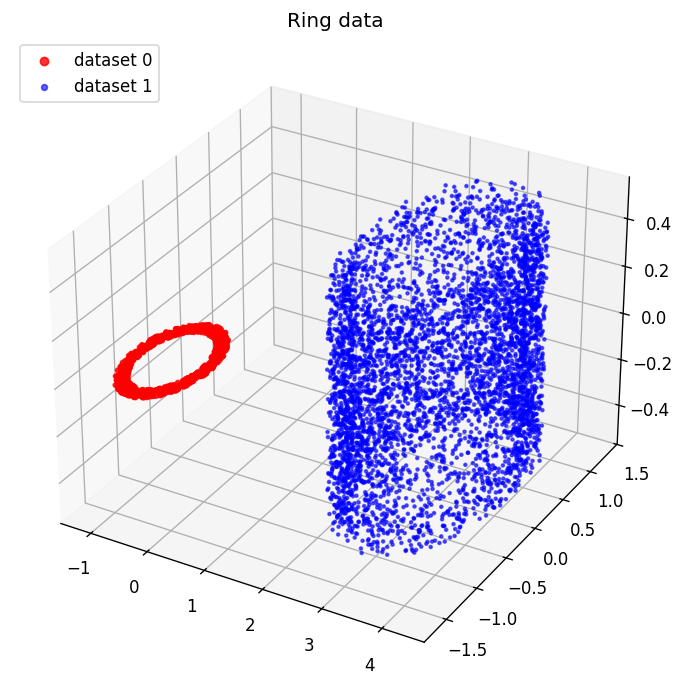

x0: (1000, 3), x1: (5000, 3), P: (1000, 5000), P.sum=1.000000


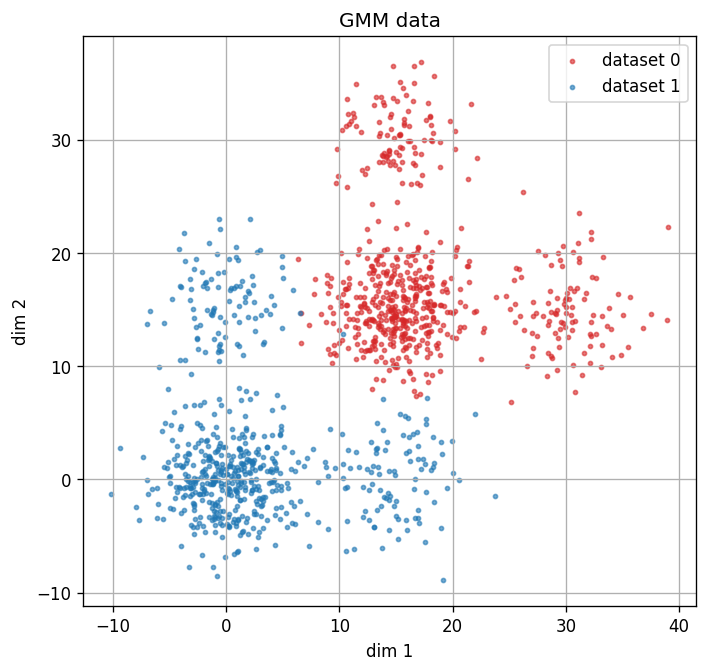

gmm observed data: x0=(600, 1000), x1=(600, 1000) (p=1000, q=6, theta=3.0)


In [5]:
x0_demo, x1_demo, P_demo = load_or_compute_plan(seed_demo)

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x0_demo[:, 0], x0_demo[:, 1], x0_demo[:, 2], c="red", s=6, alpha=0.8, label="dataset 0")
ax.scatter(x1_demo[:, 0], x1_demo[:, 1], x1_demo[:, 2], c="blue", s=3, alpha=0.6, label="dataset 1")
ax.set_title("Ring data")
ax.view_init(elev=30, azim=-60)
ax.legend(markerscale=2, loc="upper left")
plt.show()

print(f"x0: {x0_demo.shape}, x1: {x1_demo.shape}, P: {P_demo.shape}, P.sum={P_demo.sum():.6f}")

# GMM data with batch effect (before OT plan / t-SNE)
gmm_n0, gmm_n1 = 600, 600
gmm_p, gmm_q, gmm_theta = 1000, 6, 3.0

gmm0_obs, gmm1_obs = make_joint_gmm(
    n0=gmm_n0,
    n1=gmm_n1,
    p=gmm_p,
    q=gmm_q,
    theta=gmm_theta,
    seed=seed_demo,
    clean=False,
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(gmm0_obs[:, 0], gmm0_obs[:, 1], s=6, c="tab:red", alpha=0.6, label="dataset 0")
ax.scatter(gmm1_obs[:, 0], gmm1_obs[:, 1], s=6, c="tab:blue", alpha=0.6, label="dataset 1")
ax.set_title("GMM data")
ax.set_xlabel("dim 1")
ax.set_ylabel("dim 2")
ax.set_aspect("equal")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

print(
    f"gmm observed data: x0={gmm0_obs.shape}, x1={gmm1_obs.shape} "
    f"(p={gmm_p}, q={gmm_q}, theta={gmm_theta})"
)


## Baseline: OT Plan -> Sym Sparse Diag -> 4-Block Matrix + t-SNE

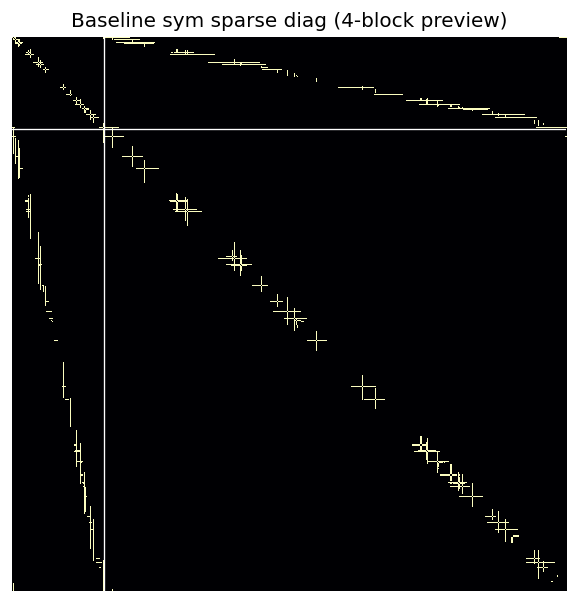

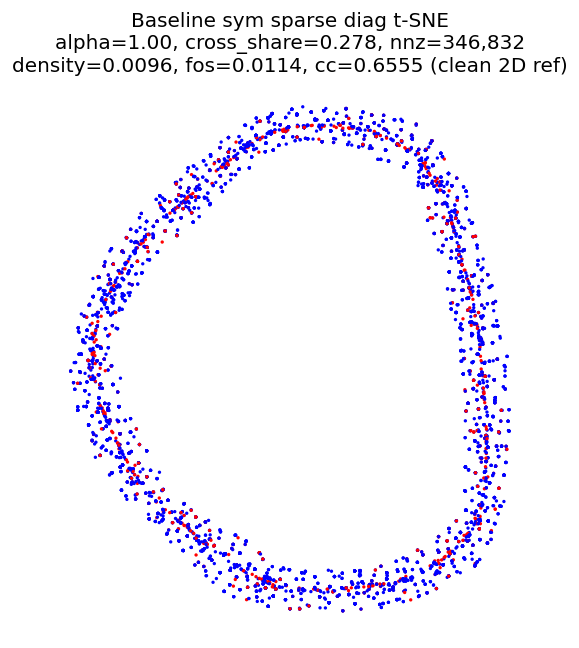

In [73]:
baseline = run_baseline_sym_sparse_diag(seed_demo, recompute=False)

# plot baseline 4-block matrix preview
preview = baseline["matrix_preview"]
boundary = _block_boundary(preview.shape[0])

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(preview, cmap="magma", interpolation="nearest")
ax.axhline(boundary - 0.5, color="white", linewidth=0.8)
ax.axvline(boundary - 0.5, color="white", linewidth=0.8)
ax.set_title("Baseline sym sparse diag (4-block preview)")
ax.axis("off")
plt.show()

# plot baseline t-SNE
embd = baseline["embd"]
colors = np.array(["r"] * n0 + ["b"] * n1)
order = np.random.default_rng(0).permutation(n0 + n1)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*embd[order].T, c=colors[order], s=1, rasterized=True)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(
    f"Baseline sym sparse diag t-SNE\n"
    f"alpha={baseline['cross_block_alpha']:.2f}, cross_share={baseline['block_cross_share']:.3f}, nnz={baseline['graph_nnz']:,}\n"
    f"density={baseline['graph_density']:.4f}, fos={baseline['foscttm']:.4f}, cc={baseline['cross_concordance']:.4f} (clean 2D ref)"
)
plt.show()


## New Methods


/tmp/ipykernel_1568362/647391354.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


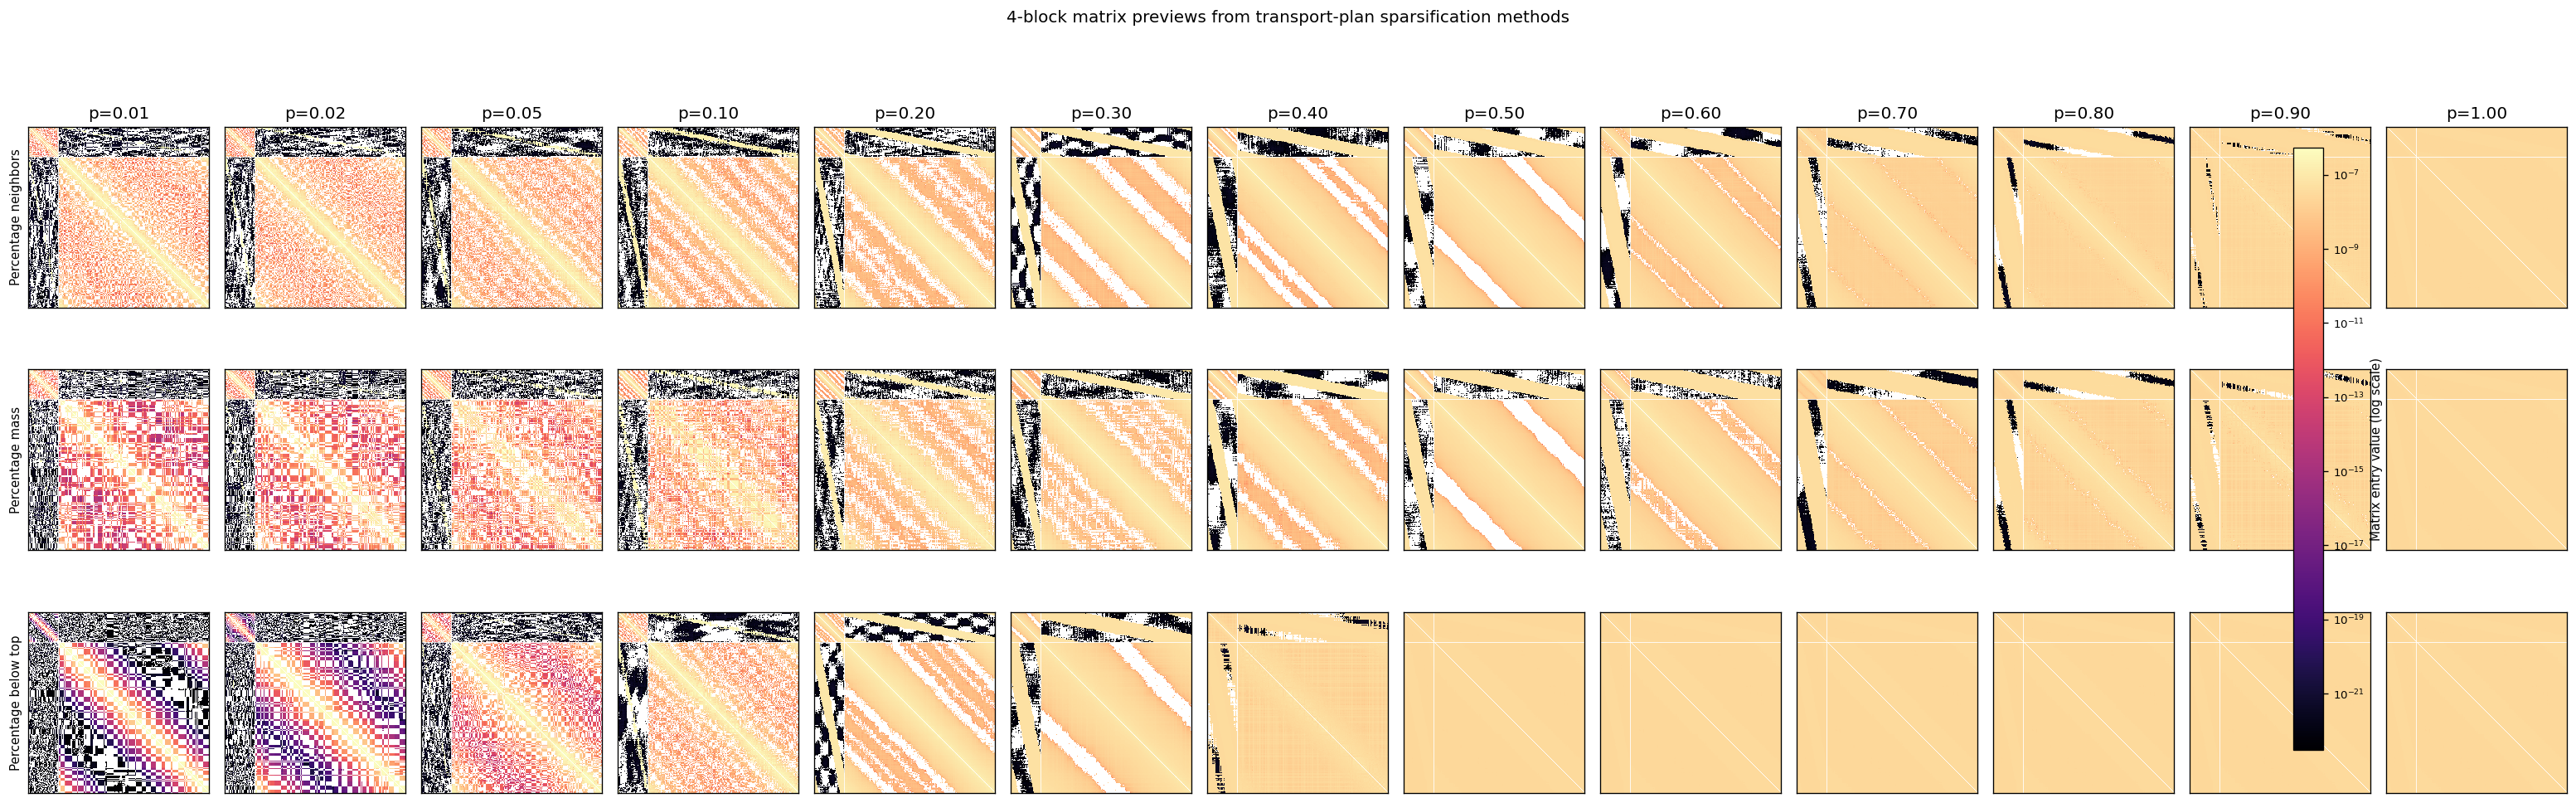

In [74]:
# Ensure demo runs exist for matrix gallery
demo_runs = {}
for method in methods:
    for p in percentages:
        demo_runs[(method, p)] = run_setting(seed_demo, method, p, recompute=False)

all_previews = [demo_runs[(method, p)]["matrix_preview"] for method in methods for p in percentages]
all_vals = np.concatenate([arr.ravel() for arr in all_previews])
pos_vals = all_vals[all_vals > 0]

# Robust shared scaling across all panels to avoid one outlier making everything black.
if pos_vals.size == 0:
    vmin, vmax = 1e-12, 1.0
else:
    vmin = float(np.quantile(pos_vals, 0.02))
    vmax = float(np.quantile(pos_vals, 0.995))
    if vmax <= vmin:
        vmax = vmin * 10.0

norm = LogNorm(vmin=vmin, vmax=vmax)

fig, axes = plt.subplots(len(methods), len(percentages), figsize=(2.0 * len(percentages), 2.8 * len(methods)))
im = None

for r, method in enumerate(methods):
    for c, p in enumerate(percentages):
        run = demo_runs[(method, p)]
        preview = run["matrix_preview"]
        boundary = _block_boundary(preview.shape[0])

        # Keep zeros black while using log scale for positive entries.
        disp = np.array(preview, copy=True)
        disp[disp <= 0] = np.nan

        ax = axes[r, c] if len(methods) > 1 else axes[c]
        im = ax.imshow(
            disp,
            cmap="magma",
            interpolation="nearest",
            norm=norm,
        )
        ax.axhline(boundary - 0.5, color="white", linewidth=0.5)
        ax.axvline(boundary - 0.5, color="white", linewidth=0.5)
        ax.set_xticks([])
        ax.set_yticks([])

        if r == 0:
            ax.set_title(f"p={p:.2f}")
        if c == 0:
            ax.set_ylabel(method_labels[method], fontsize=9)

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.015, pad=0.01)
cbar.set_label("Matrix entry value (log scale)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

fig.suptitle("4-block matrix previews from transport-plan sparsification methods", y=1.02)
fig.tight_layout()
plt.show()


## t-SNE Results for New Methods


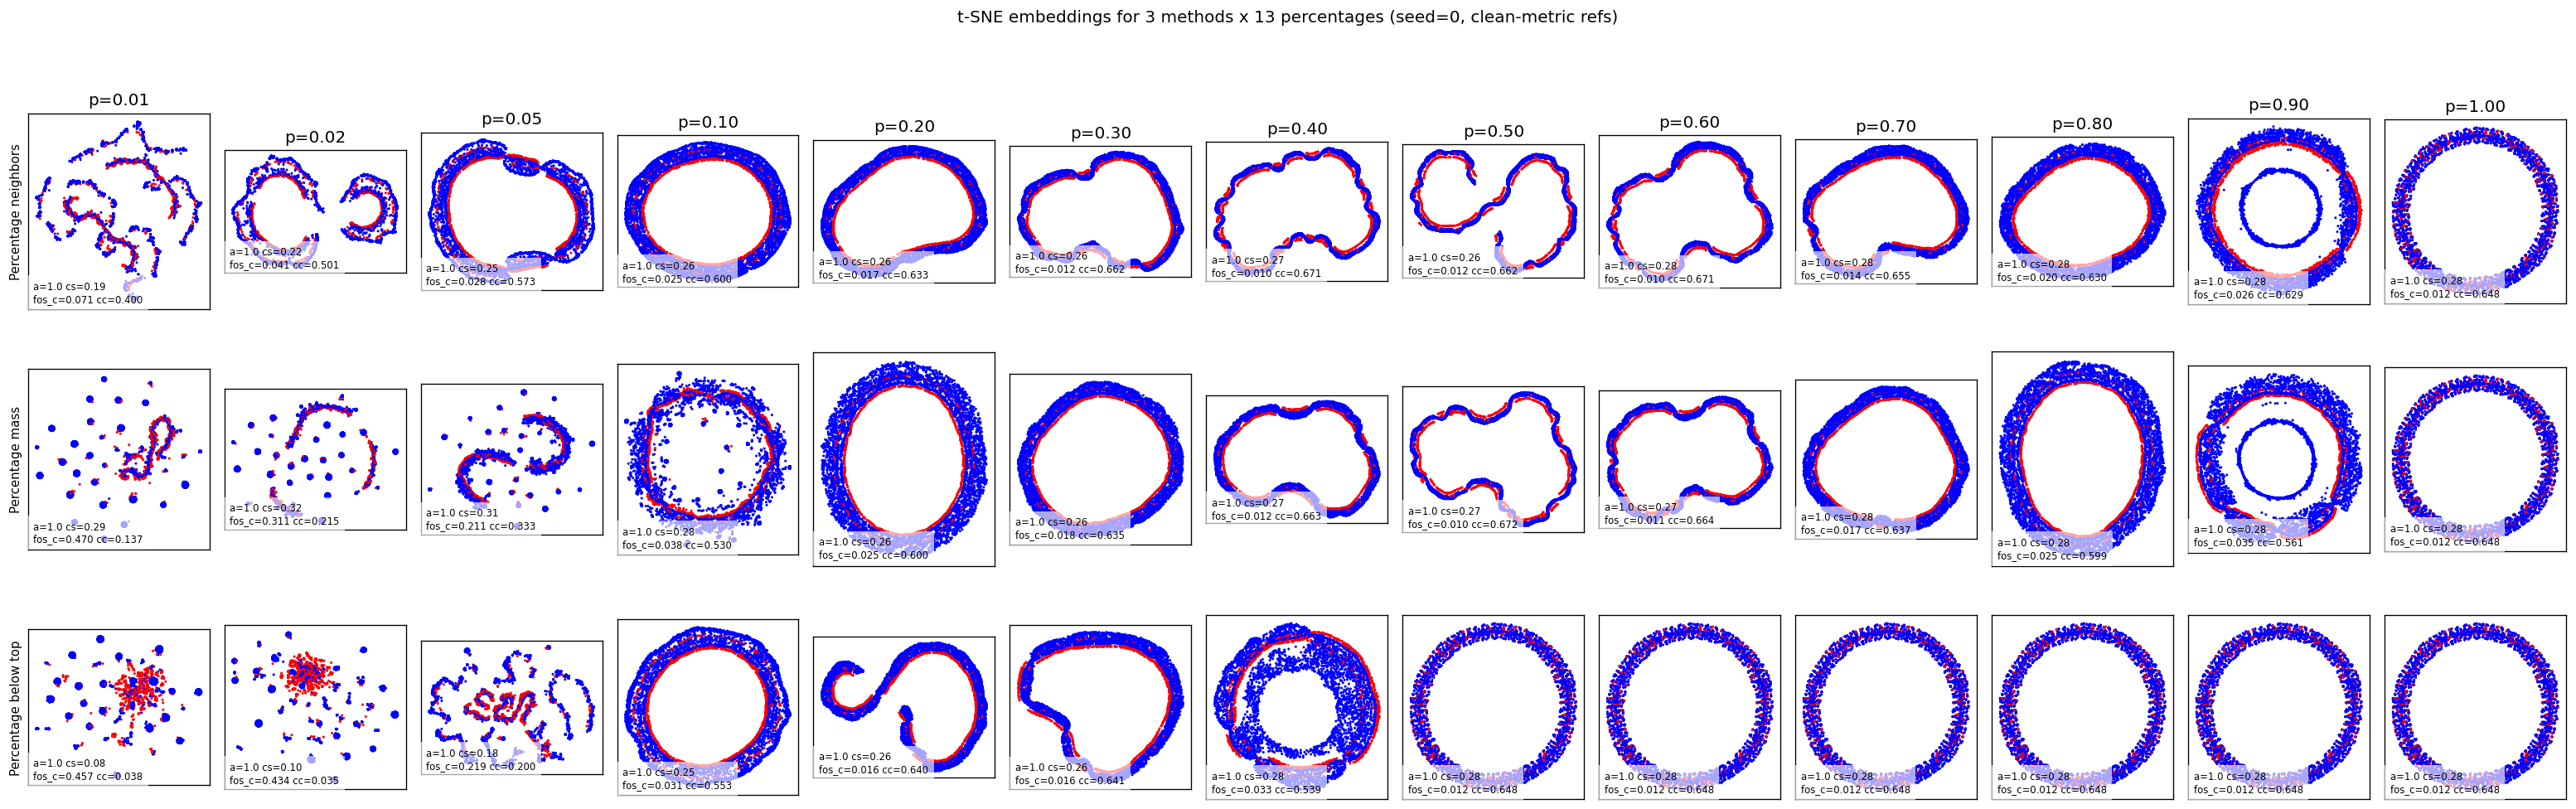

In [75]:
fig, axes = plt.subplots(len(methods), len(percentages), figsize=(2.0 * len(percentages), 2.8 * len(methods)))
colors = np.array(["r"] * n0 + ["b"] * n1)
order = np.random.default_rng(0).permutation(n0 + n1)

for r, method in enumerate(methods):
    for c, p in enumerate(percentages):
        run = run_setting(seed_demo, method, p, recompute=False)
        embd = run["embd"]

        ax = axes[r, c] if len(methods) > 1 else axes[c]
        ax.scatter(*embd[order].T, c=colors[order], s=0.7, rasterized=True)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])

        if r == 0:
            ax.set_title(f"p={p:.2f}")
        if c == 0:
            ax.set_ylabel(method_labels[method], fontsize=9)

        ax.text(
            0.03,
            0.04,
            f"a={run['cross_block_alpha']:.1f} cs={run['block_cross_share']:.2f}\n"
            f"fos_c={run['foscttm']:.3f} cc={run['cross_concordance']:.3f}",
            transform=ax.transAxes,
            fontsize=7,
            bbox={"facecolor": "white", "alpha": 0.65, "edgecolor": "none"},
        )

fig.suptitle(f"t-SNE embeddings for 3 methods x {len(percentages)} percentages (seed={seed_demo}, clean-metric refs)", y=1.02)
fig.tight_layout()
plt.show()


## No scaling, binary and simmetry


In [76]:
NO_AFF_REFERENCE = METRIC_REFERENCE + "_no_aff_v1"


def run_file_path_no_aff(seed, method, percentage, cross_alpha=None):
    alpha = cross_block_alpha if cross_alpha is None else float(cross_alpha)
    return no_aff_cache_dir / (
        f"seed{seed}_{method}_pct{_pct_tag(percentage)}_alpha{_alpha_tag(alpha)}_bte{_bte_tag(below_top_scale_exponent)}_noaff.npz"
    )


def _load_run_no_aff(path):
    run = np.load(path, allow_pickle=True)
    required = [
        "seed",
        "method",
        "percentage",
        "cross_block_alpha",
        "below_top_scale_exponent",
        "embd",
        "foscttm",
        "cross_concordance",
        "block_cross_share",
        "graph_nnz",
        "graph_density",
        "time_sparsify",
        "time_graph",
        "time_tsne",
        "metric_reference",
    ]
    missing = [k for k in required if k not in run.files]
    if missing:
        raise KeyError(f"Missing keys in no-aff cache: {missing}")

    metric_reference = str(run["metric_reference"])
    if metric_reference != NO_AFF_REFERENCE:
        raise KeyError(f"no-aff metric_reference={metric_reference}, expected {NO_AFF_REFERENCE}")

    return {
        "seed": int(run["seed"]),
        "method": str(run["method"]),
        "percentage": float(run["percentage"]),
        "cross_block_alpha": float(run["cross_block_alpha"]),
        "below_top_scale_exponent": float(run["below_top_scale_exponent"]),
        "embd": run["embd"],
        "foscttm": float(run["foscttm"]),
        "cross_concordance": float(run["cross_concordance"]),
        "block_cross_share": float(run["block_cross_share"]),
        "graph_nnz": int(run["graph_nnz"]),
        "graph_density": float(run["graph_density"]),
        "time_sparsify": float(run["time_sparsify"]),
        "time_graph": float(run["time_graph"]),
        "time_tsne": float(run["time_tsne"]),
    }


def run_setting_no_aff(seed, method, percentage, recompute=False, cross_alpha=None):
    alpha = cross_block_alpha if cross_alpha is None else float(cross_alpha)
    path = run_file_path_no_aff(seed, method, percentage, cross_alpha=alpha)
    if path.exists() and not recompute:
        try:
            out = _load_run_no_aff(path)
            if not np.isclose(out["cross_block_alpha"], alpha):
                raise KeyError("cross_block_alpha mismatch")
            if not np.isclose(out["below_top_scale_exponent"], below_top_scale_exponent):
                raise KeyError("below_top_scale_exponent mismatch")
            return out
        except KeyError:
            print(f"Legacy/incompatible no-aff cache at {path.name}; recomputing.")

    x0, x1, P = load_or_compute_plan(seed)
    n0_seed, n1_seed = x0.shape[0], x1.shape[0]
    clean0, clean1 = load_clean_reference(seed, n0_ref=n0_seed, n1_ref=n1_seed)

    t0 = time.time()
    P_sparse, _ = sparsify_transport_plan(
        P,
        method=method,
        percentage=percentage,
        ensure_nonempty=True,
        renormalize=True,
        return_stats=True,
        below_top_scale_exponent=below_top_scale_exponent,
    )
    t1 = time.time()

    A = get_diag_graph(P_sparse)
    A = reweight_cross_blocks(A, n0_block=n0_seed, alpha=alpha, renormalize=True)
    block_stats = block_mass_stats(A, n0_seed)

    graph = sp.csr_matrix(A / A.sum())
    graph.sum_duplicates()
    t2 = time.time()

    embd = np.asarray(aligned_tsne(graph, n_epochs=n_epochs, seed=seed))
    t3 = time.time()

    embd0 = embd[:n0_seed]
    embd1 = embd[n0_seed:]
    foscttm = float(compute_foscttm(clean0, clean1, embd0, embd1))
    k_cross = min(cross_k, n0_seed, n1_seed)
    cross_concordance = float(compute_cross_concordance(clean0, clean1, embd0, embd1, k=k_cross))

    np.savez(
        path,
        seed=int(seed),
        method=str(method),
        percentage=float(percentage),
        cross_block_alpha=float(alpha),
        below_top_scale_exponent=float(below_top_scale_exponent),
        embd=embd,
        foscttm=foscttm,
        cross_concordance=cross_concordance,
        block_cross_share=float(block_stats["cross_share"]),
        graph_nnz=int(graph.nnz),
        graph_density=float(graph.nnz / (graph.shape[0] * graph.shape[1])),
        time_sparsify=float(t1 - t0),
        time_graph=float(t2 - t1),
        time_tsne=float(t3 - t2),
        metric_reference=NO_AFF_REFERENCE,
    )

    return _load_run_no_aff(path)


In [77]:
# Self-contained point-1 ablation table (does not depend on earlier `df` cell)
ablation_seeds = [seed_demo]  # set e.g. [0] for fast run, or sweep_seeds for full run

rows_scaled = []
rows_no_aff = []

for seed in ablation_seeds:
    for method in methods:
        for p in percentages:
            run_scaled = run_setting(seed, method, p, recompute=False, cross_alpha=cross_block_alpha)
            run_no_aff = run_setting_no_aff(seed, method, p, recompute=False, cross_alpha=cross_block_alpha)

            rows_scaled.append(
                {
                    "seed": run_scaled["seed"],
                    "method": run_scaled["method"],
                    "percentage": run_scaled["percentage"],
                    "cross_block_alpha": run_scaled["cross_block_alpha"],
                    "foscttm": run_scaled["foscttm"],
                    "cross_concordance": run_scaled["cross_concordance"],
                    "block_cross_share": run_scaled["block_cross_share"],
                    "graph_density": run_scaled["graph_density"],
                    "time_tsne": run_scaled["time_tsne"],
                    "pipeline": "scaled_bin_sym",
                }
            )
            rows_no_aff.append(
                {
                    "seed": run_no_aff["seed"],
                    "method": run_no_aff["method"],
                    "percentage": run_no_aff["percentage"],
                    "cross_block_alpha": run_no_aff["cross_block_alpha"],
                    "foscttm": run_no_aff["foscttm"],
                    "cross_concordance": run_no_aff["cross_concordance"],
                    "block_cross_share": run_no_aff["block_cross_share"],
                    "graph_density": run_no_aff["graph_density"],
                    "time_tsne": run_no_aff["time_tsne"],
                    "pipeline": "no_scaled_bin_sym",
                }
            )

expected_rows = len(ablation_seeds) * len(methods) * len(percentages)
assert len(rows_scaled) == expected_rows
assert len(rows_no_aff) == expected_rows

df_compare = pd.DataFrame(rows_scaled + rows_no_aff).sort_values(["pipeline", "method", "percentage", "seed"]).reset_index(drop=True)

compare_summary = (
    df_compare.groupby(["pipeline", "method", "percentage"], as_index=False)
    .agg(
        foscttm_mean=("foscttm", "mean"),
        foscttm_std=("foscttm", "std"),
        cc_mean=("cross_concordance", "mean"),
        cc_std=("cross_concordance", "std"),
        cross_share_mean=("block_cross_share", "mean"),
        cross_share_std=("block_cross_share", "std"),
    )
)

print(f"Done point-1 ablation rows per pipeline: {expected_rows}")
compare_summary.head()


Done point-1 ablation rows per pipeline: 39


,pipeline,method,percentage,foscttm_mean,foscttm_std,cc_mean,cc_std,cross_share_mean,cross_share_std
0,no_scaled_bin_sym,percentage_below_top,0.01,0.035194,NaN,0.459599,NaN,0.082091,NaN
1,no_scaled_bin_sym,percentage_below_top,0.02,0.036332,NaN,0.440610,NaN,0.098099,NaN
2,no_scaled_bin_sym,percentage_below_top,0.05,0.028473,NaN,0.528782,NaN,0.178565,NaN
3,no_scaled_bin_sym,percentage_below_top,0.10,0.028406,NaN,0.482817,NaN,0.249076,NaN
4,no_scaled_bin_sym,percentage_below_top,0.20,0.013181,NaN,0.656929,NaN,0.264462,NaN


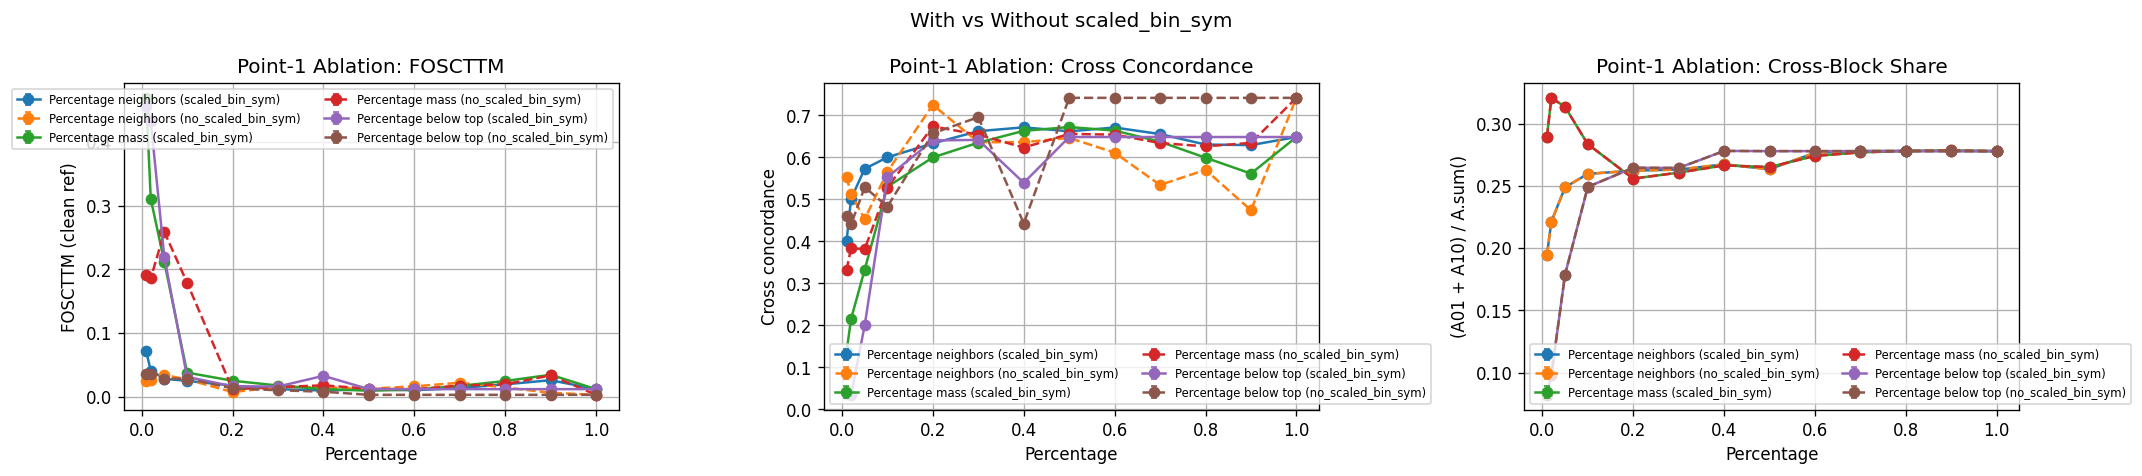

In [78]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharex=True)

for method in methods:
    for pipeline, ls in [("scaled_bin_sym", "-"), ("no_scaled_bin_sym", "--")]:
        part = compare_summary[(compare_summary["method"] == method) & (compare_summary["pipeline"] == pipeline)].sort_values("percentage")
        label = f"{method_labels[method]} ({pipeline})"

        axes[0].errorbar(part["percentage"], part["foscttm_mean"], yerr=part["foscttm_std"], marker="o", capsize=2, linestyle=ls, label=label)
        axes[1].errorbar(part["percentage"], part["cc_mean"], yerr=part["cc_std"], marker="o", capsize=2, linestyle=ls, label=label)
        axes[2].errorbar(part["percentage"], part["cross_share_mean"], yerr=part["cross_share_std"], marker="o", capsize=2, linestyle=ls, label=label)

axes[0].set_title("Point-1 Ablation: FOSCTTM")
axes[0].set_xlabel("Percentage")
axes[0].set_ylabel("FOSCTTM (clean ref)")

axes[1].set_title("Point-1 Ablation: Cross Concordance")
axes[1].set_xlabel("Percentage")
axes[1].set_ylabel("Cross concordance")

axes[2].set_title("Point-1 Ablation: Cross-Block Share")
axes[2].set_xlabel("Percentage")
axes[2].set_ylabel("(A01 + A10) / A.sum()")

for ax in axes:
    ax.legend(fontsize=7, ncol=2)

fig.suptitle("With vs Without scaled_bin_sym")
fig.tight_layout()
plt.show()


## Quantile Remap Method


In [79]:
# Diagonal block quantile remap (A00 and A11 only)
def remap_diag_block_quantiles(
    A,
    n0_block,
    qmin=0.01,
    qmax=0.99,
    gamma=1.5,
    blend=0.7,
    preserve_block_mass=True,
):
    A_out = np.array(A, copy=True)

    def _remap_block(B):
        B = np.array(B, copy=True)
        n = B.shape[0]

        offdiag = np.ones_like(B, dtype=bool)
        np.fill_diagonal(offdiag, False)
        mask = offdiag & (B > 0)
        vals = B[mask]

        if vals.size < 2:
            np.fill_diagonal(B, 0)
            return B

        order = np.argsort(vals)
        ranks = np.empty_like(order, dtype=float)
        ranks[order] = np.arange(vals.size, dtype=float)
        q = ranks / max(vals.size - 1, 1)

        q = np.clip((q - qmin) / max(qmax - qmin, 1e-12), 0.0, 1.0)
        q = q ** gamma

        Bq = np.zeros_like(B)
        Bq[mask] = q
        Bq = 0.5 * (Bq + Bq.T)
        np.fill_diagonal(Bq, 0)

        Bout = (1.0 - blend) * B + blend * Bq
        Bout = 0.5 * (Bout + Bout.T)
        np.fill_diagonal(Bout, 0)

        if preserve_block_mass:
            s_old = float(B.sum())
            s_new = float(Bout.sum())
            if s_new > 0:
                Bout *= s_old / s_new

        return Bout

    A_out[:n0_block, :n0_block] = _remap_block(A_out[:n0_block, :n0_block])
    A_out[n0_block:, n0_block:] = _remap_block(A_out[n0_block:, n0_block:])
    np.fill_diagonal(A_out, 0)

    s = float(A_out.sum())
    if s > 0:
        A_out /= s
    return A_out


REMAP_QMIN = 0.01
REMAP_QMAX = 0.99
REMAP_GAMMA = 1.5
REMAP_BLEND = 0.7

REMAP_REFERENCE = (
    NO_AFF_REFERENCE
    + f"_diagremap_q{REMAP_QMIN:.2f}_{REMAP_QMAX:.2f}_g{REMAP_GAMMA:.2f}_b{REMAP_BLEND:.2f}"
)


def run_file_path_no_aff_remap(seed, method, percentage, cross_alpha=None):
    alpha = cross_block_alpha if cross_alpha is None else float(cross_alpha)
    return no_aff_cache_dir / (
        f"seed{seed}_{method}_pct{_pct_tag(percentage)}_alpha{_alpha_tag(alpha)}"
        f"_bte{_bte_tag(below_top_scale_exponent)}_diagremap.npz"
    )


def _load_run_no_aff_remap(path):
    run = np.load(path, allow_pickle=True)
    required = [
        "seed", "method", "percentage", "cross_block_alpha", "below_top_scale_exponent",
        "embd", "foscttm", "cross_concordance", "block_cross_share",
        "graph_nnz", "graph_density", "time_sparsify", "time_graph", "time_tsne",
        "metric_reference",
    ]
    missing = [k for k in required if k not in run.files]
    if missing:
        raise KeyError(f"Missing keys in remap cache: {missing}")

    metric_reference = str(run["metric_reference"])
    if metric_reference != REMAP_REFERENCE:
        raise KeyError(f"remap metric_reference={metric_reference}, expected {REMAP_REFERENCE}")

    return {
        "seed": int(run["seed"]),
        "method": str(run["method"]),
        "percentage": float(run["percentage"]),
        "cross_block_alpha": float(run["cross_block_alpha"]),
        "below_top_scale_exponent": float(run["below_top_scale_exponent"]),
        "embd": run["embd"],
        "foscttm": float(run["foscttm"]),
        "cross_concordance": float(run["cross_concordance"]),
        "block_cross_share": float(run["block_cross_share"]),
        "graph_nnz": int(run["graph_nnz"]),
        "graph_density": float(run["graph_density"]),
        "time_sparsify": float(run["time_sparsify"]),
        "time_graph": float(run["time_graph"]),
        "time_tsne": float(run["time_tsne"]),
    }


def run_setting_no_aff_remap(seed, method, percentage, recompute=False, cross_alpha=None):
    alpha = cross_block_alpha if cross_alpha is None else float(cross_alpha)
    path = run_file_path_no_aff_remap(seed, method, percentage, cross_alpha=alpha)
    if path.exists() and not recompute:
        try:
            out = _load_run_no_aff_remap(path)
            if not np.isclose(out["cross_block_alpha"], alpha):
                raise KeyError("cross_block_alpha mismatch")
            if not np.isclose(out["below_top_scale_exponent"], below_top_scale_exponent):
                raise KeyError("below_top_scale_exponent mismatch")
            return out
        except KeyError:
            print(f"Legacy/incompatible remap cache at {path.name}; recomputing.")

    x0, x1, P = load_or_compute_plan(seed)
    n0_seed, n1_seed = x0.shape[0], x1.shape[0]
    clean0, clean1 = load_clean_reference(seed, n0_ref=n0_seed, n1_ref=n1_seed)

    t0 = time.time()
    P_sparse, _ = sparsify_transport_plan(
        P,
        method=method,
        percentage=percentage,
        ensure_nonempty=True,
        renormalize=True,
        return_stats=True,
        below_top_scale_exponent=below_top_scale_exponent,
    )
    t1 = time.time()

    A = get_diag_graph(P_sparse)
    A = remap_diag_block_quantiles(
        A,
        n0_block=n0_seed,
        qmin=REMAP_QMIN,
        qmax=REMAP_QMAX,
        gamma=REMAP_GAMMA,
        blend=REMAP_BLEND,
        preserve_block_mass=True,
    )
    A = reweight_cross_blocks(A, n0_block=n0_seed, alpha=alpha, renormalize=True)
    block_stats = block_mass_stats(A, n0_seed)

    graph = sp.csr_matrix(A / A.sum())
    graph.sum_duplicates()
    t2 = time.time()

    embd = np.asarray(aligned_tsne(graph, n_epochs=n_epochs, seed=seed))
    t3 = time.time()

    embd0 = embd[:n0_seed]
    embd1 = embd[n0_seed:]
    foscttm = float(compute_foscttm(clean0, clean1, embd0, embd1))
    k_cross = min(cross_k, n0_seed, n1_seed)
    cross_concordance = float(compute_cross_concordance(clean0, clean1, embd0, embd1, k=k_cross))

    np.savez(
        path,
        seed=int(seed),
        method=str(method),
        percentage=float(percentage),
        cross_block_alpha=float(alpha),
        below_top_scale_exponent=float(below_top_scale_exponent),
        embd=embd,
        foscttm=foscttm,
        cross_concordance=cross_concordance,
        block_cross_share=float(block_stats["cross_share"]),
        graph_nnz=int(graph.nnz),
        graph_density=float(graph.nnz / (graph.shape[0] * graph.shape[1])),
        time_sparsify=float(t1 - t0),
        time_graph=float(t2 - t1),
        time_tsne=float(t3 - t2),
        metric_reference=REMAP_REFERENCE,
    )

    return _load_run_no_aff_remap(path)


In [80]:
# Try the method at the bottom (default: one method to keep runtime reasonable).
remap_methods = [alpha_compare_method]  # change to `methods` for full run
sweep_seeds = [seed_demo]  # set e.g. [0] for fast run, or sweep_seeds for full run
rows_remap = []
rows_no_remap = []

for method in remap_methods:
    for seed in sweep_seeds:
        for p in percentages:
            base = run_setting_no_aff(seed, method, p, recompute=False, cross_alpha=cross_block_alpha)
            remp = run_setting_no_aff_remap(seed, method, p, recompute=False, cross_alpha=cross_block_alpha)

            rows_no_remap.append(
                {
                    "pipeline": "no_aff_raw",
                    "method": method,
                    "seed": seed,
                    "percentage": p,
                    "foscttm": base["foscttm"],
                    "cross_concordance": base["cross_concordance"],
                    "block_cross_share": base["block_cross_share"],
                }
            )
            rows_remap.append(
                {
                    "pipeline": "no_aff_diag_quantile_remap",
                    "method": method,
                    "seed": seed,
                    "percentage": p,
                    "foscttm": remp["foscttm"],
                    "cross_concordance": remp["cross_concordance"],
                    "block_cross_share": remp["block_cross_share"],
                }
            )

df_remap_compare = pd.DataFrame(rows_no_remap + rows_remap)
summary_remap_compare = (
    df_remap_compare.groupby(["pipeline", "method", "percentage"], as_index=False)
    .agg(
        foscttm_mean=("foscttm", "mean"),
        foscttm_std=("foscttm", "std"),
        cc_mean=("cross_concordance", "mean"),
        cc_std=("cross_concordance", "std"),
        cross_share_mean=("block_cross_share", "mean"),
        cross_share_std=("block_cross_share", "std"),
    )
)

summary_remap_compare.head()


--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence -0.2630, 50 iterations in 5.5012 sec
   --> Time elapsed: 7.03 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.8854, 50 iterations in 5.4689 sec
Iteration  100, KL divergence 0.8248, 50 iterations in 5.4043 sec
   --> Time elapsed: 14.27 seconds
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exagge

,pipeline,method,percentage,foscttm_mean,foscttm_std,cc_mean,cc_std,cross_share_mean,cross_share_std
0,no_aff_diag_quantile_remap,percentage_neighbors,0.01,0.050485,NaN,0.326616,NaN,0.194017,NaN
1,no_aff_diag_quantile_remap,percentage_neighbors,0.02,0.044418,NaN,0.327467,NaN,0.221227,NaN
2,no_aff_diag_quantile_remap,percentage_neighbors,0.05,0.035817,NaN,0.423041,NaN,0.248754,NaN
3,no_aff_diag_quantile_remap,percentage_neighbors,0.10,0.026418,NaN,0.569116,NaN,0.259546,NaN
4,no_aff_diag_quantile_remap,percentage_neighbors,0.20,0.011779,NaN,0.701848,NaN,0.262159,NaN


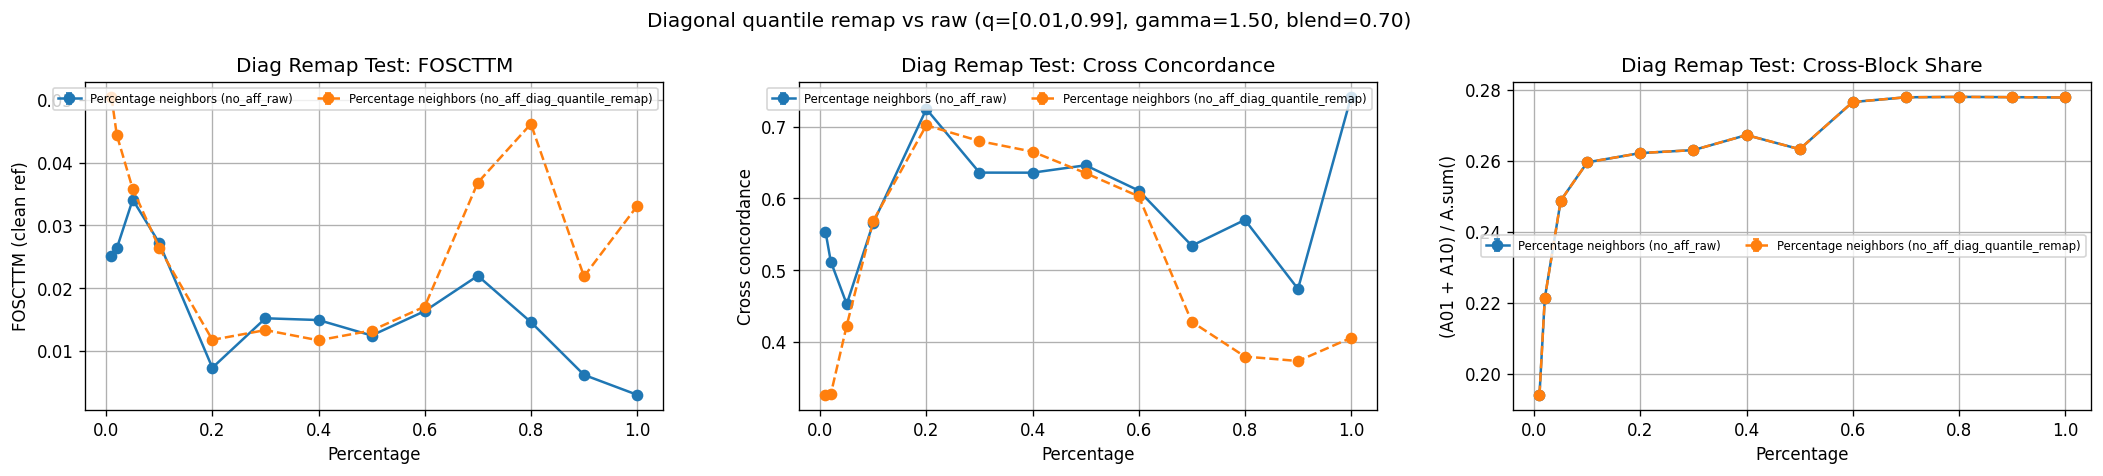

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharex=True)

for method in remap_methods:
    for pipeline, ls in [("no_aff_raw", "-"), ("no_aff_diag_quantile_remap", "--")]:
        part = summary_remap_compare[
            (summary_remap_compare["method"] == method)
            & (summary_remap_compare["pipeline"] == pipeline)
        ].sort_values("percentage")
        label = f"{method_labels[method]} ({pipeline})"

        axes[0].errorbar(part["percentage"], part["foscttm_mean"], yerr=part["foscttm_std"], marker="o", capsize=2, linestyle=ls, label=label)
        axes[1].errorbar(part["percentage"], part["cc_mean"], yerr=part["cc_std"], marker="o", capsize=2, linestyle=ls, label=label)
        axes[2].errorbar(part["percentage"], part["cross_share_mean"], yerr=part["cross_share_std"], marker="o", capsize=2, linestyle=ls, label=label)

axes[0].set_title("Diag Remap Test: FOSCTTM")
axes[0].set_xlabel("Percentage")
axes[0].set_ylabel("FOSCTTM (clean ref)")

axes[1].set_title("Diag Remap Test: Cross Concordance")
axes[1].set_xlabel("Percentage")
axes[1].set_ylabel("Cross concordance")

axes[2].set_title("Diag Remap Test: Cross-Block Share")
axes[2].set_xlabel("Percentage")
axes[2].set_ylabel("(A01 + A10) / A.sum()")

for ax in axes:
    ax.legend(fontsize=7, ncol=2)

fig.suptitle(
    f"Diagonal quantile remap vs raw (q=[{REMAP_QMIN:.2f},{REMAP_QMAX:.2f}], gamma={REMAP_GAMMA:.2f}, blend={REMAP_BLEND:.2f})"
)
fig.tight_layout()
plt.show()


/tmp/ipykernel_1568362/1601307740.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


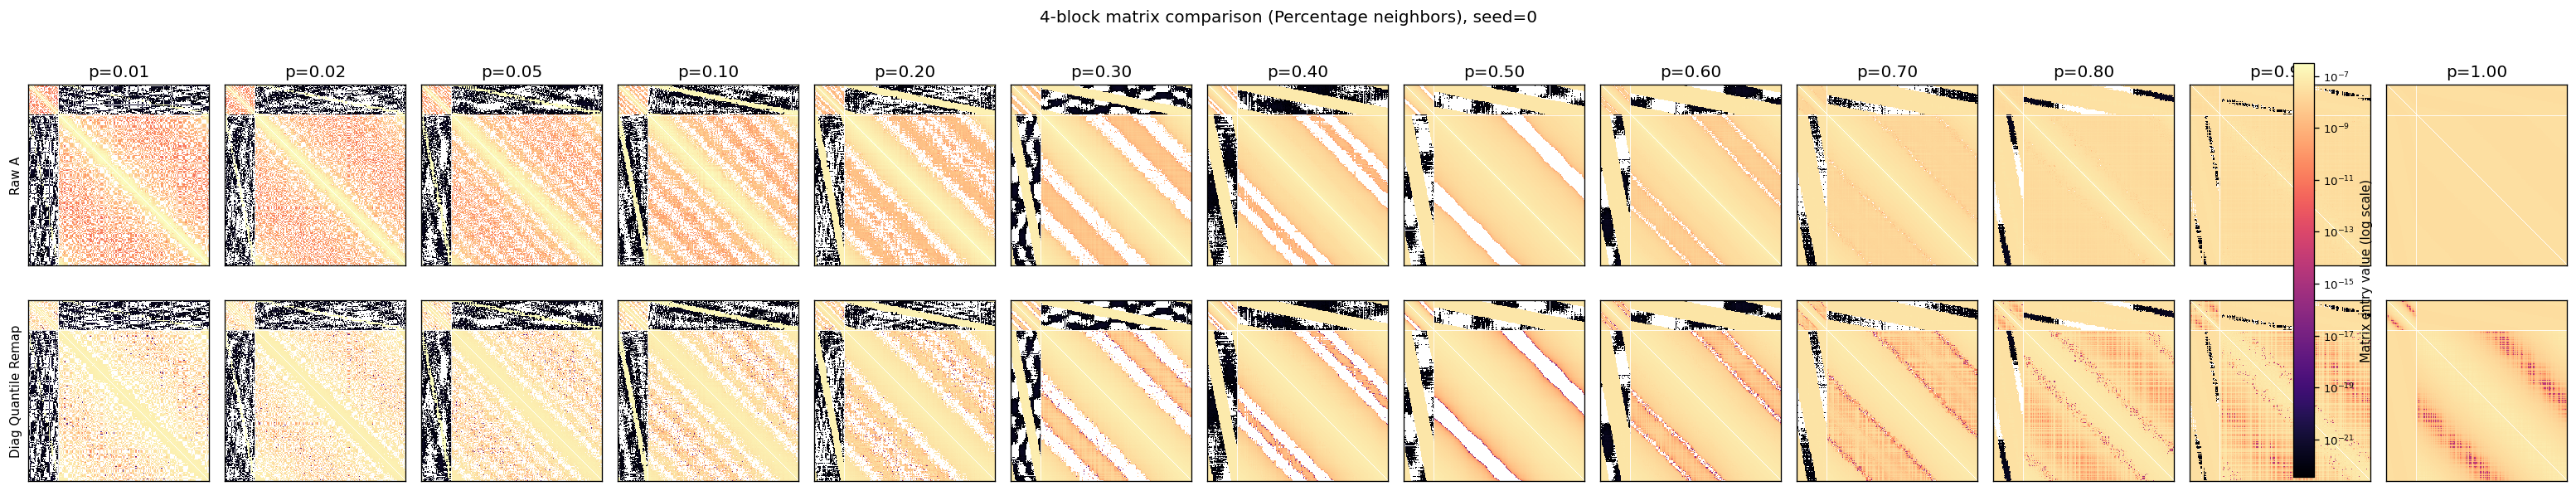

In [82]:
# Cell 1: 4-block matrices (raw vs diag-quantile-remap), direct A graph branch
viz_seed = seed_demo
viz_methods = remap_methods                 # e.g. ["percentage_neighbors"]
viz_percentages = percentages               # or subset, e.g. [0.01, 0.05, 0.1, 0.3, 0.6, 1.0]
viz_max_side = 420

pipelines = [
    ("no_aff_raw", "Raw A"),
    ("no_aff_diag_quantile_remap", "Diag Quantile Remap"),
]

def _build_A_for_pipeline(seed, method, p, pipeline):
    x0_, x1_, P_ = load_or_compute_plan(seed)
    n0_ = len(x0_)

    P_sparse = sparsify_transport_plan(
        P_,
        method=method,
        percentage=p,
        ensure_nonempty=True,
        renormalize=True,
        return_stats=False,
        below_top_scale_exponent=below_top_scale_exponent,
    )

    A = get_diag_graph(P_sparse)

    if pipeline == "no_aff_diag_quantile_remap":
        A = remap_diag_block_quantiles(
            A,
            n0_block=n0_,
            qmin=REMAP_QMIN,
            qmax=REMAP_QMAX,
            gamma=REMAP_GAMMA,
            blend=REMAP_BLEND,
            preserve_block_mass=True,
        )

    A = reweight_cross_blocks(A, n0_block=n0_, alpha=cross_block_alpha, renormalize=True)
    return A

for method in viz_methods:
    previews = {}
    all_vals = []

    for pipeline, _ in pipelines:
        for p in viz_percentages:
            A = _build_A_for_pipeline(viz_seed, method, p, pipeline)
            preview, _ = _downsample_dense(A, max_side=viz_max_side)
            previews[(pipeline, p)] = preview

            vals = preview[preview > 0]
            if vals.size > 0:
                all_vals.append(vals)

    if len(all_vals) == 0:
        vmin, vmax = 1e-12, 1.0
    else:
        pos = np.concatenate(all_vals)
        vmin = float(np.quantile(pos, 0.02))
        vmax = float(np.quantile(pos, 0.995))
        if vmax <= vmin:
            vmax = vmin * 10.0

    norm = LogNorm(vmin=vmin, vmax=vmax)

    fig, axes = plt.subplots(
        len(pipelines),
        len(viz_percentages),
        figsize=(2.0 * len(viz_percentages), 2.7 * len(pipelines)),
    )
    im = None

    for r, (pipeline, row_label) in enumerate(pipelines):
        for c, p in enumerate(viz_percentages):
            ax = axes[r, c] if len(pipelines) > 1 else axes[c]
            preview = previews[(pipeline, p)]
            boundary = _block_boundary(preview.shape[0])

            disp = preview.copy()
            disp[disp <= 0] = np.nan

            im = ax.imshow(disp, cmap="magma", interpolation="nearest", norm=norm)
            ax.axhline(boundary - 0.5, color="white", linewidth=0.5)
            ax.axvline(boundary - 0.5, color="white", linewidth=0.5)
            ax.set_xticks([])
            ax.set_yticks([])

            if r == 0:
                ax.set_title(f"p={p:.2f}")
            if c == 0:
                ax.set_ylabel(row_label, fontsize=9)

    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.015, pad=0.01)
    cbar.set_label("Matrix entry value (log scale)", fontsize=9)
    cbar.ax.tick_params(labelsize=8)

    fig.suptitle(f"4-block matrix comparison ({method_labels[method]}), seed={viz_seed}")
    fig.tight_layout()
    plt.show()

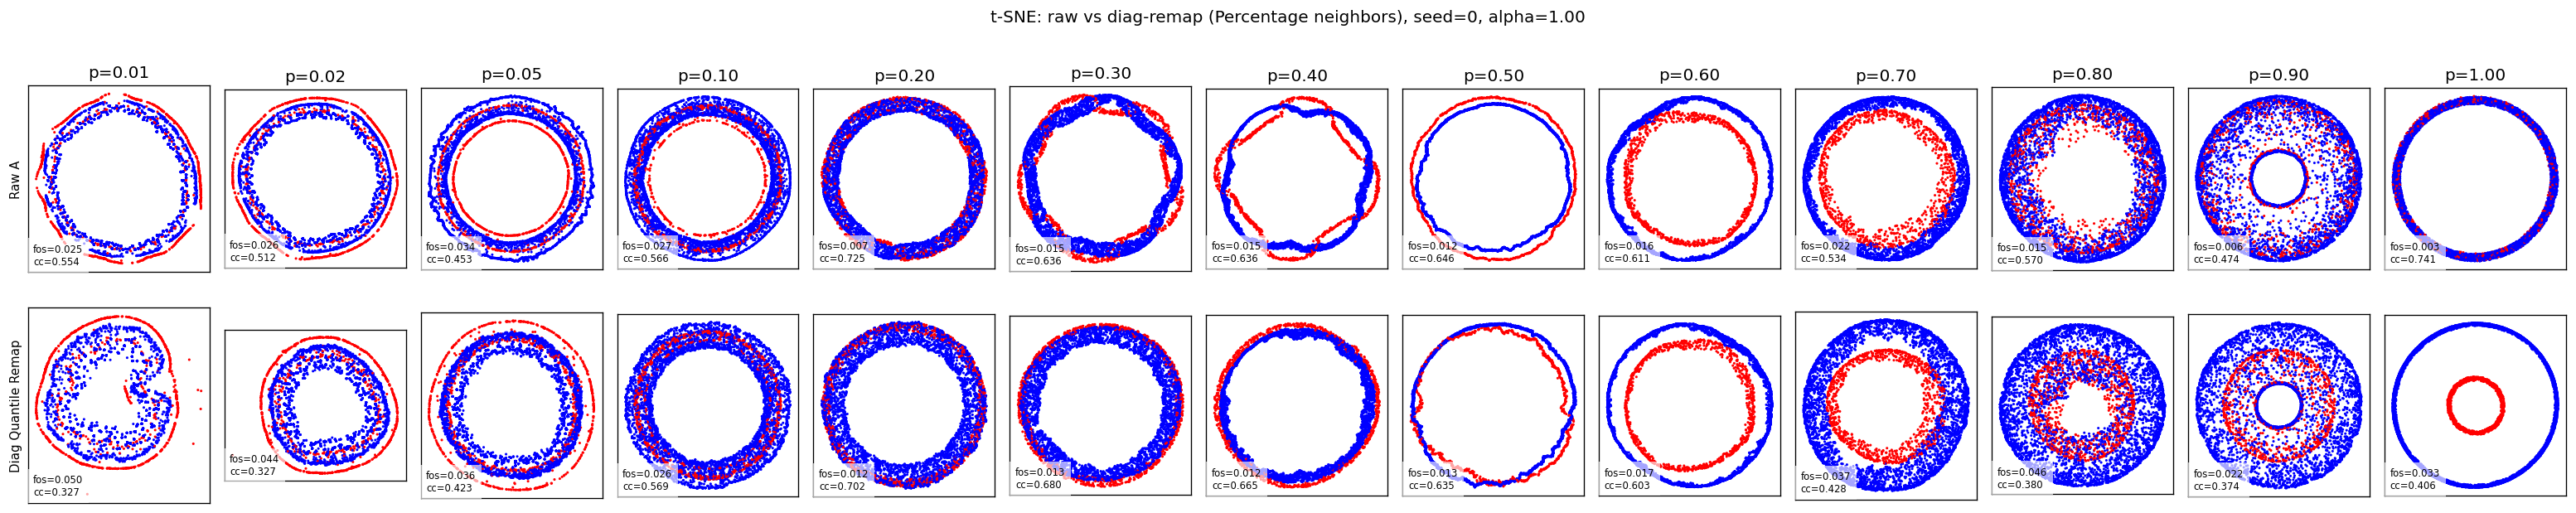

In [83]:
# Cell 2: t-SNE visualizations (raw vs diag-quantile-remap), same settings
viz_seed = seed_demo
viz_methods = remap_methods
viz_percentages = percentages  # or subset for readability

pipelines = [
    ("no_aff_raw", run_setting_no_aff, "Raw A"),
    ("no_aff_diag_quantile_remap", run_setting_no_aff_remap, "Diag Quantile Remap"),
]

colors = np.array(["r"] * n0 + ["b"] * n1)
order = np.random.default_rng(0).permutation(n0 + n1)

for method in viz_methods:
    fig, axes = plt.subplots(
        len(pipelines),
        len(viz_percentages),
        figsize=(2.0 * len(viz_percentages), 2.8 * len(pipelines)),
    )

    for r, (pipeline_key, runner, row_label) in enumerate(pipelines):
        for c, p in enumerate(viz_percentages):
            run = runner(viz_seed, method, p, recompute=False, cross_alpha=cross_block_alpha)
            embd = run["embd"]

            ax = axes[r, c] if len(pipelines) > 1 else axes[c]
            ax.scatter(*embd[order].T, c=colors[order], s=0.7, rasterized=True)
            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])

            if r == 0:
                ax.set_title(f"p={p:.2f}")
            if c == 0:
                ax.set_ylabel(row_label, fontsize=9)

            ax.text(
                0.03,
                0.04,
                f"fos={run['foscttm']:.3f}\ncc={run['cross_concordance']:.3f}",
                transform=ax.transAxes,
                fontsize=7,
                bbox={"facecolor": "white", "alpha": 0.65, "edgecolor": "none"},
            )

    fig.suptitle(
        f"t-SNE: raw vs diag-remap ({method_labels[method]}), seed={viz_seed}, alpha={cross_block_alpha:.2f}"
    )
    fig.tight_layout()
    plt.show()
